**ФИО студента:** [Иванов Иван Иванович]

**Задание:** [выберите между `inpainting` / `outpainting`]

**Группа:** [номер группы]

**Дата сдачи:** [дата]

## Блок настройки окружения

Код для импорта библиотек, для формирования глобальных констант, других конфигураций (если требуется). Постарайтесь здесь зафиксировать все seed, которые сможете

In [1]:
import os
import random

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import hashlib
from pathlib import Path
import time

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import Image, display
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"
MLFLOW_EXPERIMENT_NAME = "outpainting"
MLFLOW_MODEL_NAME = "outpainting_unet"

try:
    import mlflow
    from mlflow.exceptions import MlflowException
    from mlflow.tracking import MlflowClient

    mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
    mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)
    MLFLOW_AVAILABLE = True
except Exception:
    MLFLOW_AVAILABLE = False

print(f"Трекинг MLflow: {'включен' if MLFLOW_AVAILABLE else 'отключен'}")



2026/11/24 12:12:01 INFO mlflow.tracking.fluent: Experiment with name 'outpainting' does not exist. Creating a new experiment.


Трекинг MLflow: включен


## Блок "Данные"

Входной файл проверяется по SHA-256, форме и заполнению области пропусков нулями: в данных пропуски хранятся как 0. Куб предзагружен в оперативную память, поэтому копирование патчей в датасете быстрее, чем чтение из mmap.

Пять соседних срезов дают модели 2.5D-контекст по глубине: центральный срез восстанавливается с учётом двух предыдущих и двух следующих. Патч 368×256 увеличивает известный контекст, остаётся кратным 16 и полностью помещается в известной области между граничными полосами. Скрытые полосы шириной 24 сверху и снизу повторяют реальные граничные области куба.

Для train положение патча, отражения, масштаб амплитуд и гауссов шум генерируются заново при каждом обращении к примеру, поэтому состав обучающих данных меняется между эпохами. Шум добавляется только в известные значения входа; целевой срез и канал маски остаются чистыми. Validation и test используют фиксированные примеры без аугментации.

Разбиение выполнено по индексам центральных срезов, а не по отдельным пикселям. Между train, validation и test оставлены защитные интервалы, поэтому их пятисрезовые контексты не пересекаются и данные не протекают между выборками.


In [2]:
DATA_PATH = Path("input_seismic_data/outpainting_cube_missed_data.npy")
EXPECTED_SHAPE = (460, 481, 800)
EXPECTED_SHA256 = "b33681e31f22c7cfa21de6b96f17e640a981f3ead16579b0656f063a4b9231fa"

sha256 = hashlib.sha256()
with DATA_PATH.open("rb") as file:
    for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
        sha256.update(chunk)

actual_sha256 = sha256.hexdigest()
assert actual_sha256 == EXPECTED_SHA256, (
    f"SHA-256 не совпадает: ожидался {EXPECTED_SHA256}, получен {actual_sha256}"
)

cube = np.load(DATA_PATH)
assert cube.shape == EXPECTED_SHAPE
assert cube.dtype == np.float32
print(cube.shape)

real_mask = np.zeros(cube.shape, dtype=bool)
real_mask[:, :24, :] = True
real_mask[:, 457:481, :] = True

for slice_index in range(cube.shape[0]):
    assert np.all(cube[slice_index][real_mask[slice_index]] == 0), (
        f"Область пропусков в срезе {slice_index} содержит ненулевые значения"
    )

missing_count = int(real_mask.sum())
print(
    f"Проверка нулей пройдена: {missing_count:,} пропущенных значений, "
    f"{100 * missing_count / cube.size:.2f}% куба"
)

PATCH_H = 368
PATCH_W = 256

MASK_W = 24

assert 457 - 24 >= PATCH_H
assert cube.shape[2] >= PATCH_W
assert PATCH_H % 16 == 0 and PATCH_W % 16 == 0
assert 2 * MASK_W < PATCH_H

AMP_SCALE_RANGE = (0.9, 1.1)
NOISE_SIGMA = 0.05


(460, 481, 800)
Проверка нулей пройдена: 17,664,000 пропущенных значений, 9.98% куба


In [3]:
sample = cube[::4, ::4, ::4]
sample_known = ~real_mask[::4, ::4, ::4]
mean = float(sample[sample_known].mean())
std = max(float(sample[sample_known].std()), 1e-6)


In [4]:
def make_sample(rng, center, augment):
    y = int(rng.integers(24, 457 - PATCH_H + 1))
    z = int(rng.integers(0, 800 - PATCH_W + 1))
    flip_h = augment and bool(rng.integers(2))
    flip_v = augment and bool(rng.integers(2))
    amp_scale = float(rng.uniform(*AMP_SCALE_RANGE)) if augment else 1.0
    noise_sigma = float(rng.uniform(0.0, NOISE_SIGMA)) if augment else 0.0
    return center, y, z, flip_h, flip_v, amp_scale, noise_sigma


def make_samples(centers, samples_per_center, augment, seed):
    rng = np.random.default_rng(seed)
    return [
        make_sample(rng, int(center), augment)
        for center in centers
        for _ in range(samples_per_center)
    ]


In [5]:
class OutpaintingDataset(Dataset):
    def __init__(
        self,
        cube,
        centers,
        samples_per_center,
        mean,
        std,
        augment,
        seed,
        dynamic
    ):
        self.cube = cube
        self.centers = centers
        self.samples_per_center = samples_per_center
        self.mean = mean
        self.std = std
        self.augment = augment
        self.dynamic = dynamic
        self.rng = np.random.default_rng(seed)
        self.samples = None if dynamic else make_samples(
            centers,
            samples_per_center,
            augment,
            seed
        )

    def __len__(self):
        return len(self.centers) * self.samples_per_center

    def get_sample(self, index):
        if self.samples is not None:
            return self.samples[index]
        center = int(self.centers[index // self.samples_per_center])
        return make_sample(self.rng, center, self.augment)

    def __getitem__(self, index):
        center, y, z, flip_h, flip_v, amp_scale, noise_sigma = self.get_sample(index)
        patch = self.cube[
            center - 2:center + 3,
            y:y + PATCH_H,
            z:z + PATCH_W
        ].copy()
        target = patch[2].copy()

        patch = (patch - self.mean) / self.std
        target = (target - self.mean) / self.std
        patch *= amp_scale
        target *= amp_scale
        if noise_sigma:
            noise = self.rng.standard_normal(patch.shape)
            patch += noise.astype(np.float32) * noise_sigma

        mask = np.zeros((PATCH_H, PATCH_W), dtype=np.float32)
        mask[:MASK_W, :] = 1
        mask[-MASK_W:, :] = 1
        patch *= (1 - mask)[None]

        if flip_h:
            patch = patch[:, :, ::-1]
            target = target[:, ::-1]
            mask = mask[:, ::-1]

        if flip_v:
            patch = patch[:, ::-1, :]
            target = target[::-1, :]
            mask = mask[::-1, :]

        inputs = np.concatenate((patch, mask[None]), axis=0)

        return (
            torch.from_numpy(inputs.copy()).float(),
            torch.from_numpy(target[None].copy()).float(),
            torch.from_numpy(mask[None].copy()).float()
        )


In [6]:
train_centers = np.arange(2, 322)
val_centers = np.arange(326, 396)
test_centers = np.arange(400, 458)
TRAIN_SAMPLES_PER_CENTER = 4

train_dataset = OutpaintingDataset(
    cube, train_centers, TRAIN_SAMPLES_PER_CENTER, mean, std, True, 42, True
)
val_dataset = OutpaintingDataset(cube, val_centers, 4, mean, std, False, 43, False)
test_dataset = OutpaintingDataset(cube, test_centers, 4, mean, std, False, 44, False)


In [7]:
BATCH_SIZE = 16
NUM_WORKERS = 0

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)


## Блок "Модель"

Используется полносвёрточная 2.5D U-Net: пять соседних срезов и маска пропусков подаются как шесть каналов. `AvgPool2d` сохраняет усреднённую структуру подписанных амплитуд. Для восстановления разрешения применяются nearest-интерполяция и свёртка 3×3. GroupNorm стабилизирует обучение при небольшом batch size.

В bottleneck добавлены свёртки с `dilation = 2` и `dilation = 4`. Они расширяют рецептивное поле без дополнительного уменьшения разрешения, чтобы центральная часть большой маски получала информацию от известных границ. Размер батча уменьшен до 16 из-за увеличенных патчей и дополнительного слоя.


In [8]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.GELU(),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.GELU()
        )

    def forward(self, x):
        return self.block(x)


class DilatedBottleneck(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.GroupNorm(8, out_channels),
            nn.GELU(),
            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=2,
                dilation=2,
                bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.GELU(),
            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=4,
                dilation=4,
                bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.GELU()
        )

    def forward(self, x):
        return self.block(x)


In [9]:
class UNet25D(nn.Module):
    def __init__(self, in_channels=6, out_channels=1, base_channels=32):
        super().__init__()
        self.pool = nn.AvgPool2d(2)
        self.encoders = nn.ModuleList([
            ConvBlock(in_channels, base_channels),
            ConvBlock(base_channels, base_channels * 2),
            ConvBlock(base_channels * 2, base_channels * 4),
            ConvBlock(base_channels * 4, base_channels * 8)
        ])
        self.bottleneck = DilatedBottleneck(base_channels * 8, base_channels * 16)
        self.upconvs = nn.ModuleList([
            nn.Conv2d(base_channels * 16, base_channels * 8, 3, padding=1),
            nn.Conv2d(base_channels * 8, base_channels * 4, 3, padding=1),
            nn.Conv2d(base_channels * 4, base_channels * 2, 3, padding=1),
            nn.Conv2d(base_channels * 2, base_channels, 3, padding=1)
        ])
        self.decoders = nn.ModuleList([
            ConvBlock(base_channels * 16, base_channels * 8),
            ConvBlock(base_channels * 8, base_channels * 4),
            ConvBlock(base_channels * 4, base_channels * 2),
            ConvBlock(base_channels * 2, base_channels)
        ])
        self.head = nn.Conv2d(base_channels, out_channels, 1)

    def forward(self, x):
        height, width = x.shape[-2:]
        pad_height = (-height) % 16
        pad_width = (-width) % 16
        x = F.pad(x, (0, pad_width, 0, pad_height))

        skips = []
        for encoder in self.encoders:
            x = encoder(x)
            skips.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)

        for upconv, decoder, skip in zip(
            self.upconvs,
            self.decoders,
            reversed(skips)
        ):
            x = F.interpolate(x, scale_factor=2, mode="nearest")
            x = upconv(x)
            x = torch.cat((x, skip), dim=1)
            x = decoder(x)

        x = self.head(x)
        return x[..., :height, :width]


model = UNet25D()
print(f"Параметров модели: {sum(p.numel() for p in model.parameters()):,}")


Параметров модели: 10,994,625


## Блок "Обучение модели"

Функция потерь объединяет маскированные L1 и MSE, исправленный градиентный член по горизонтали и вертикали, multiscale high-frequency L1 и `R_LOSS_WEIGHT · (1 − R)`. High-frequency член сравнивает отклики Sobel X, Sobel Y и Laplacian на масштабах 1, 1/2 и 1/4. Вне маски prediction заменяется известным target, поэтому фильтры на границе не обучают неизвестные внешние значения. Лучшая модель выбирается по глобальному validation R.

Основной запуск использует `GRAD_LOSS_WEIGHT = 0.3`, `HIGH_FREQ_LOSS_WEIGHT = 0.1` и `R_LOSS_WEIGHT = 0.5`. Для контрольного эксперимента без перворазностного градиентного члена нужно установить `GRAD_LOSS_WEIGHT = 0.0` и `RUN_NAME = "no-grad-l1"`, не меняя остальные параметры, и заново выполнить ноутбук с инициализации данных и модели. Это отключит только `masked_gradient_l1`; multiscale high-frequency член останется активным.

Задан лимит в `EPOCHS` эпох. Валидация, сохранение чекпоинта и ранняя остановка выполняются каждые `VALIDATION_EVERY` эпох. Для дообучения чекпоинта той же архитектуры нужно установить `RESUME = True`.


In [10]:
def masked_mse(prediction, target, mask):
    error = (prediction - target) ** 2
    return (error * mask).sum() / mask.sum().clamp_min(1)


def masked_l1(prediction, target, mask):
    error = torch.abs(prediction - target)
    return (error * mask).sum() / mask.sum().clamp_min(1)


def masked_gradient_l1(prediction, target, mask):
    mask_x = mask[..., 1:] * mask[..., :-1]
    mask_y = mask[..., 1:, :] * mask[..., :-1, :]
    error_x = (prediction[..., 1:] - prediction[..., :-1] - target[..., 1:] + target[..., :-1]).abs()
    error_y = (
        prediction[..., 1:, :] - prediction[..., :-1, :]
        - target[..., 1:, :] + target[..., :-1, :]
    ).abs()
    return (
        (error_x * mask_x).sum() + (error_y * mask_y).sum()
    ) / (mask_x.sum() + mask_y.sum()).clamp_min(1)


def masked_multiscale_high_frequency_l1(prediction, target, mask):
    with torch.autocast(device_type=prediction.device.type, enabled=False):
        prediction = prediction.float()
        target = target.float()
        mask = mask.float()
        combined_prediction = prediction * mask + target * (1 - mask)
        scaled_prediction = combined_prediction
        scaled_target = target
        scaled_mask = mask
        kernels = (
            prediction.new_tensor([
                [-1, 0, 1],
                [-2, 0, 2],
                [-1, 0, 1]
            ]).reshape(1, 1, 3, 3) / 8,
            prediction.new_tensor([
                [-1, -2, -1],
                [0, 0, 0],
                [1, 2, 1]
            ]).reshape(1, 1, 3, 3) / 8,
            prediction.new_tensor([
                [0, 1, 0],
                [1, -4, 1],
                [0, 1, 0]
            ]).reshape(1, 1, 3, 3)
        )
        total_loss = prediction.new_zeros(())
        for scale in range(3):
            normalizer = scaled_mask.sum().clamp_min(1)
            scale_loss = prediction.new_zeros(())
            for kernel in kernels:
                prediction_response = F.conv2d(scaled_prediction, kernel, padding=1)
                target_response = F.conv2d(scaled_target, kernel, padding=1)
                scale_loss = scale_loss + (
                    (prediction_response - target_response).abs() * scaled_mask
                ).sum() / normalizer
            total_loss = total_loss + scale_loss / len(kernels)
            if scale < 2:
                scaled_prediction = F.avg_pool2d(scaled_prediction, 2)
                scaled_target = F.avg_pool2d(scaled_target, 2)
                scaled_mask = F.avg_pool2d(scaled_mask, 2)
        return total_loss / 3


def masked_fourier_l1(prediction, target, mask):
    with torch.autocast(device_type=prediction.device.type, enabled=False):
        error = ((prediction - target) * mask.float()).float()
    return torch.fft.rfft2(error, norm="ortho").abs().mean()


def correlation_r(prediction, target):
    prediction = prediction - prediction.mean()
    target = target - target.mean()
    denominator = prediction.norm() * target.norm()
    return (prediction * target).sum() / denominator.clamp_min(1e-8)


def masked_r(prediction, target, mask):
    return correlation_r(
        prediction[mask.bool()].float(),
        target[mask.bool()].float(),
    )


def reconstruction_loss(prediction, target, mask):
    l1_loss = masked_l1(prediction, target, mask)
    mse_loss = masked_mse(prediction, target, mask)
    r_loss = 1 - masked_r(prediction, target, mask)
    loss = L1_WEIGHT * l1_loss + mse_loss + R_LOSS_WEIGHT * r_loss
    if GRAD_LOSS_WEIGHT > 0:
        loss = loss + GRAD_LOSS_WEIGHT * masked_gradient_l1(
            prediction,
            target,
            mask
        )
    if HIGH_FREQ_LOSS_WEIGHT > 0:
        loss = loss + HIGH_FREQ_LOSS_WEIGHT * masked_multiscale_high_frequency_l1(
            prediction,
            target,
            mask
        )
    if FOURIER_LOSS_WEIGHT > 0:
        loss = loss + FOURIER_LOSS_WEIGHT * masked_fourier_l1(
            prediction,
            target,
            mask
        )
    return loss


def new_r_moments():
    return torch.zeros(6, device=device)


def add_r_moments(moments, prediction, target, mask):
    prediction = prediction.detach()[mask.bool()].float()
    target = target[mask.bool()].float()
    update = torch.stack(
        (
            prediction.new_full((), float(prediction.numel())),
            prediction.sum(),
            target.sum(),
            (prediction * prediction).sum(),
            (target * target).sum(),
            (prediction * target).sum()
        )
    )
    return moments + update


def r_from_moments(moments):
    moments = moments.reshape(6)
    n = moments[0]
    sum_x = moments[1]
    sum_y = moments[2]
    sum_xx = moments[3]
    sum_yy = moments[4]
    sum_xy = moments[5]
    cov = n * sum_xy - sum_x * sum_y
    var_x = (n * sum_xx - sum_x * sum_x).clamp_min(1e-8)
    var_y = (n * sum_yy - sum_y * sum_y).clamp_min(1e-8)
    return (cov / (var_x.sqrt() * var_y.sqrt())).item()


In [11]:
%load_ext tensorboard
from torch.utils.tensorboard import SummaryWriter

model = UNet25D().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-5
)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

EPOCHS = 75
EARLY_STOPPING_PATIENCE = 12
VALIDATION_EVERY = 1
L1_WEIGHT = 1.0
R_LOSS_WEIGHT = 0.5
GRAD_LOSS_WEIGHT = 0.3
HIGH_FREQ_LOSS_WEIGHT = 0.1
FOURIER_LOSS_WEIGHT = 0.1
RUN_NAME = "fourier"
RESUME = False
CHECKPOINT_PATH = "best_outpainting_unet.pt"
RUN_STAMP = time.strftime("%Y-%m-%d_%H-%M-%S")
LOG_DIR = f"runs/outpainting/{RUN_STAMP}"
writer = SummaryWriter(LOG_DIR)
best_val_r = -float("inf")
start_epoch = 1
epochs_without_improvement = 0
history = {
    "train_loss": [],
    "val_loss": [],
    "train_r": [],
    "val_r": []
}

if RESUME:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
    scaler.load_state_dict(checkpoint["scaler_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_r = checkpoint["best_val_r"]
    history = checkpoint["history"]

if MLFLOW_AVAILABLE:
    if mlflow.active_run() is not None:
        mlflow.end_run()
    mlflow.start_run(run_name=f"{RUN_NAME}-epoch-{start_epoch}")
    mlflow.log_params(
        {
            "seed": SEED,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "validation_every": VALIDATION_EVERY,
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "l1_weight": L1_WEIGHT,
            "r_loss_weight": R_LOSS_WEIGHT,
            "grad_loss_weight": GRAD_LOSS_WEIGHT,
            "high_freq_loss_weight": HIGH_FREQ_LOSS_WEIGHT,
            "fourier_loss_weight": FOURIER_LOSS_WEIGHT,
            "dynamic_train_sampling": train_dataset.dynamic,
            "train_samples_per_center": TRAIN_SAMPLES_PER_CENTER,
            "patch": f"{PATCH_H}x{PATCH_W}",
            "mask": f"2x{MASK_W}",
            "param_count": sum(p.numel() for p in model.parameters()),
        }
    )
    mlflow.set_tag("model/architecture", str(model))
    mlflow.set_tag("log_dir", LOG_DIR)


In [12]:
def train_epoch():
    model.train()
    total_loss = 0
    r_moments = new_r_moments()

    for inputs, target, mask in tqdm(train_loader, desc="train", leave=False):
        inputs = inputs.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(device_type=device.type, enabled=use_amp):
            prediction = model(inputs)
            loss = reconstruction_loss(prediction, target, mask)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * inputs.size(0)
        r_moments = add_r_moments(r_moments, prediction, target, mask)

    train_r = r_from_moments(r_moments)

    return total_loss / len(train_loader.dataset), train_r



In [13]:
def validation_epoch():
    model.eval()
    total_loss = 0
    r_moments = new_r_moments()

    with torch.inference_mode():
        for inputs, target, mask in tqdm(val_loader, desc="val", leave=False):
            inputs = inputs.to(device, non_blocking=True)
            target = target.to(device, non_blocking=True)
            mask = mask.to(device, non_blocking=True)

            with torch.autocast(device_type=device.type, enabled=use_amp):
                prediction = model(inputs)
                loss = reconstruction_loss(prediction, target, mask)

            total_loss += loss.item() * inputs.size(0)
            r_moments = add_r_moments(r_moments, prediction, target, mask)

    val_r = r_from_moments(r_moments)

    return total_loss / len(val_loader.dataset), val_r



In [14]:
pbar = tqdm(range(start_epoch, EPOCHS + 1))
for epoch in pbar:
    train_loss, train_r = train_epoch()

    history["train_loss"].append(train_loss)
    history["train_r"].append(train_r)
    writer.add_scalar("Loss/train", train_loss, epoch)
    writer.add_scalar("R/train", train_r, epoch)
    writer.add_scalar("Learning rate", optimizer.param_groups[0]["lr"], epoch)

    if MLFLOW_AVAILABLE:
        mlflow.log_metric("lr", optimizer.param_groups[0]["lr"], step=epoch)

    postfix = {"train_loss": f"{train_loss:.4f}", "train_R": f"{train_r:.4f}"}

    if epoch % VALIDATION_EVERY == 0:
        val_loss, val_r = validation_epoch()
        scheduler.step(val_r)

        history["val_loss"].append(val_loss)
        history["val_r"].append(val_r)
        writer.add_scalar("Loss/validation", val_loss, epoch)
        writer.add_scalar("R/validation", val_r, epoch)

        if val_r > best_val_r:
            best_val_r = val_r
            epochs_without_improvement = 0
            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "scheduler_state_dict": scheduler.state_dict(),
                    "scaler_state_dict": scaler.state_dict(),
                    "mean": mean,
                    "std": std,
                    "epoch": epoch,
                    "best_val_r": best_val_r,
                    "history": history
                },
                CHECKPOINT_PATH
            )
        else:
            epochs_without_improvement += 1

        postfix["val_loss"] = f"{val_loss:.4f}"
        postfix["val_R"] = f"{val_r:.4f}"

        if MLFLOW_AVAILABLE:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("train_r", train_r, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("val_r", val_r, step=epoch)
            mlflow.log_metric("best_val_r", best_val_r, step=epoch)

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            pbar.set_postfix(postfix)
            break

    writer.flush()
    pbar.set_postfix(postfix)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
best_epoch = checkpoint["epoch"]
writer.close()



 39%|███▊      | 29/75 [20:06<31:53, 41.59s/it, train_loss=1.3015, train_R=0.5880, val_loss=1.4529, val_R=0.4701]


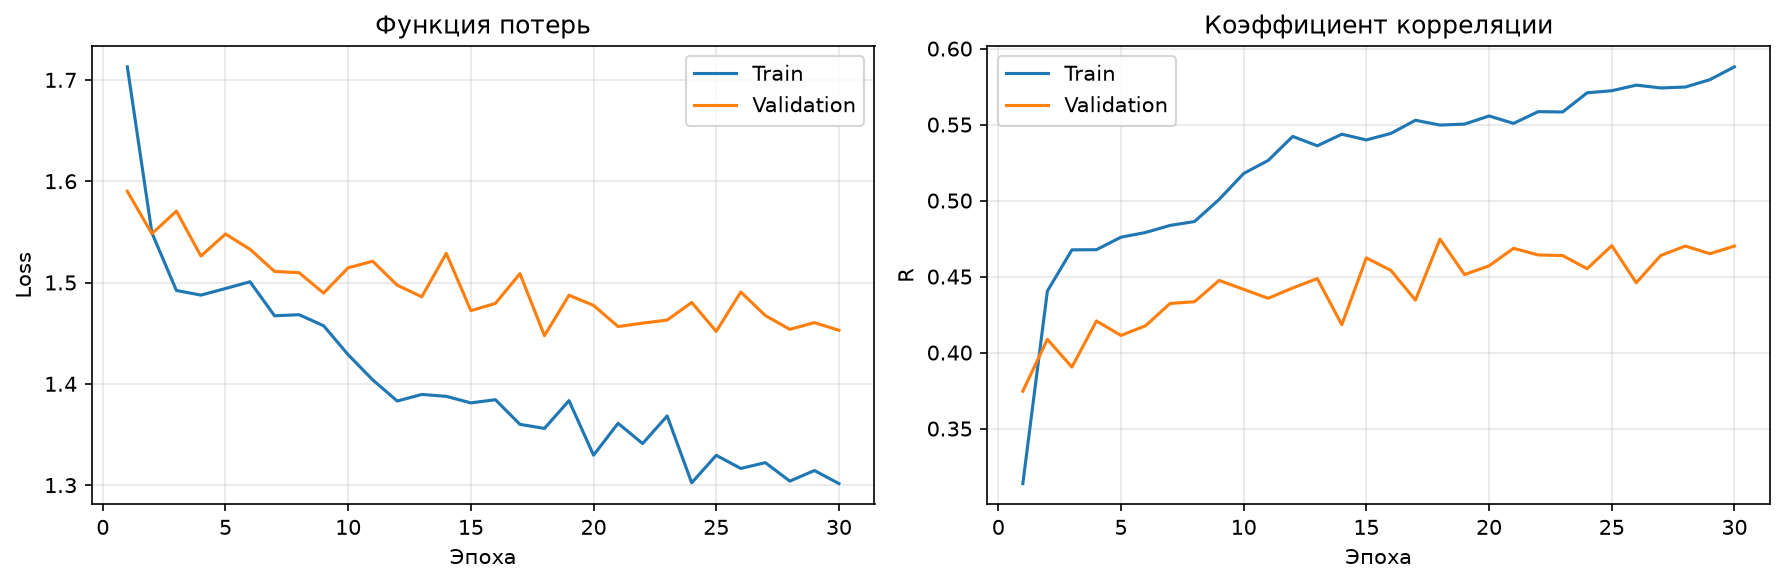

In [15]:
train_epochs = range(1, len(history["train_loss"]) + 1)
val_epochs = np.arange(
    VALIDATION_EVERY,
    len(history["val_loss"]) * VALIDATION_EVERY + 1,
    VALIDATION_EVERY
)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(train_epochs, history["train_loss"], label="Train")
axes[0].plot(val_epochs, history["val_loss"], label="Validation")
axes[0].set(title="Функция потерь", xlabel="Эпоха", ylabel="Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(train_epochs, history["train_r"], label="Train")
axes[1].plot(val_epochs, history["val_r"], label="Validation")
axes[1].set(title="Коэффициент корреляции", xlabel="Эпоха", ylabel="R")
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
fig.savefig("outpainting_training_history.png", dpi=150, bbox_inches="tight")
display(Image("outpainting_training_history.png"))



## Блок "Тестирование модели"

Модель загружается из чекпоинта `best_outpainting_unet.pt` (лучшая по валидационному R) и оценивается на тестовой выборке: средняя ошибка, коэффициент R и примеры предсказаний. При активном MLflow-запуске тестовые метрики и модель записываются на трекер, модель регистрируется в Model Registry, после чего запуск закрывается.



In [17]:
model = UNet25D().to(device)
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


UNet25D(
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (encoders): ModuleList(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(6, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
        (2): GELU(approximate='none')
        (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
        (5): GELU(approximate='none')
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (2): GELU(approximate='none')
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
        (5): GELU(approximate='none')
      )
    )
    (2): Con

In [18]:
model.eval()
test_loss = 0
prediction_values = []
target_values = []

with torch.inference_mode():
    for inputs, target, mask in test_loader:
        inputs = inputs.to(device, non_blocking=True)
        target = target.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)

        with torch.autocast(device_type=device.type, enabled=use_amp):
            prediction = model(inputs)
            loss = reconstruction_loss(prediction, target, mask)

        test_loss += loss.item() * inputs.size(0)
        prediction_values.append(prediction[mask.bool()].float().cpu())
        target_values.append(target[mask.bool()].float().cpu())

test_loss /= len(test_loader.dataset)
test_predictions = torch.cat(prediction_values)
test_targets = torch.cat(target_values)
test_r = correlation_r(test_predictions, test_targets).item()

best_train_r = history["train_r"][best_epoch - 1] if history["train_r"] else 0
best_val_r = history["val_r"][best_epoch // VALIDATION_EVERY - 1] if history["val_r"] else 0
print(f"Test loss: {test_loss:.6f} | Test R: {test_r:.4f}")
print(
    f"Итоговые R | train: {best_train_r:.4f} | "
    f"val: {best_val_r:.4f} | test: {test_r:.4f}"
)

if MLFLOW_AVAILABLE and mlflow.active_run() is not None:
    mlflow.log_metric("test_loss", test_loss)
    mlflow.log_metric("test_r", test_r)
    model_info = mlflow.pytorch.log_model(
        model,
        artifact_path=MLFLOW_MODEL_NAME,
        serialization_format="pickle",
    )
    try:
        MlflowClient().create_registered_model(MLFLOW_MODEL_NAME)
    except MlflowException:
        pass
    MlflowClient().create_model_version(
        name=MLFLOW_MODEL_NAME,
        source=model_info.model_uri,
        run_id=mlflow.active_run().info.run_id,
        tags={"best-val-r": str(best_val_r)},
    )
    mlflow.end_run()



2026/11/24 12:32:17 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Test loss: 1.462897 | Test R: 0.5178
Итоговые R | train: 0.5497 | val: 0.4747 | test: 0.5178


2026/11/24 12:32:18 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/11/24 12:32:18 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cu134) contains a local version label (+cu134). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/11/24 12:32:31 WARNING mlflow.utils.requirements_utils: Found torch version (2.15.0+cu134) contains a local version label (+cu134). MLflow logged a pip requirement for this package as 'torch==2.15.0' without the local version la

🏃 View run grad-l1-epoch-1 at: http://127.0.0.1:5000/#/experiments/3/runs/90c9167f5e4e49b5924a4999376d818f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


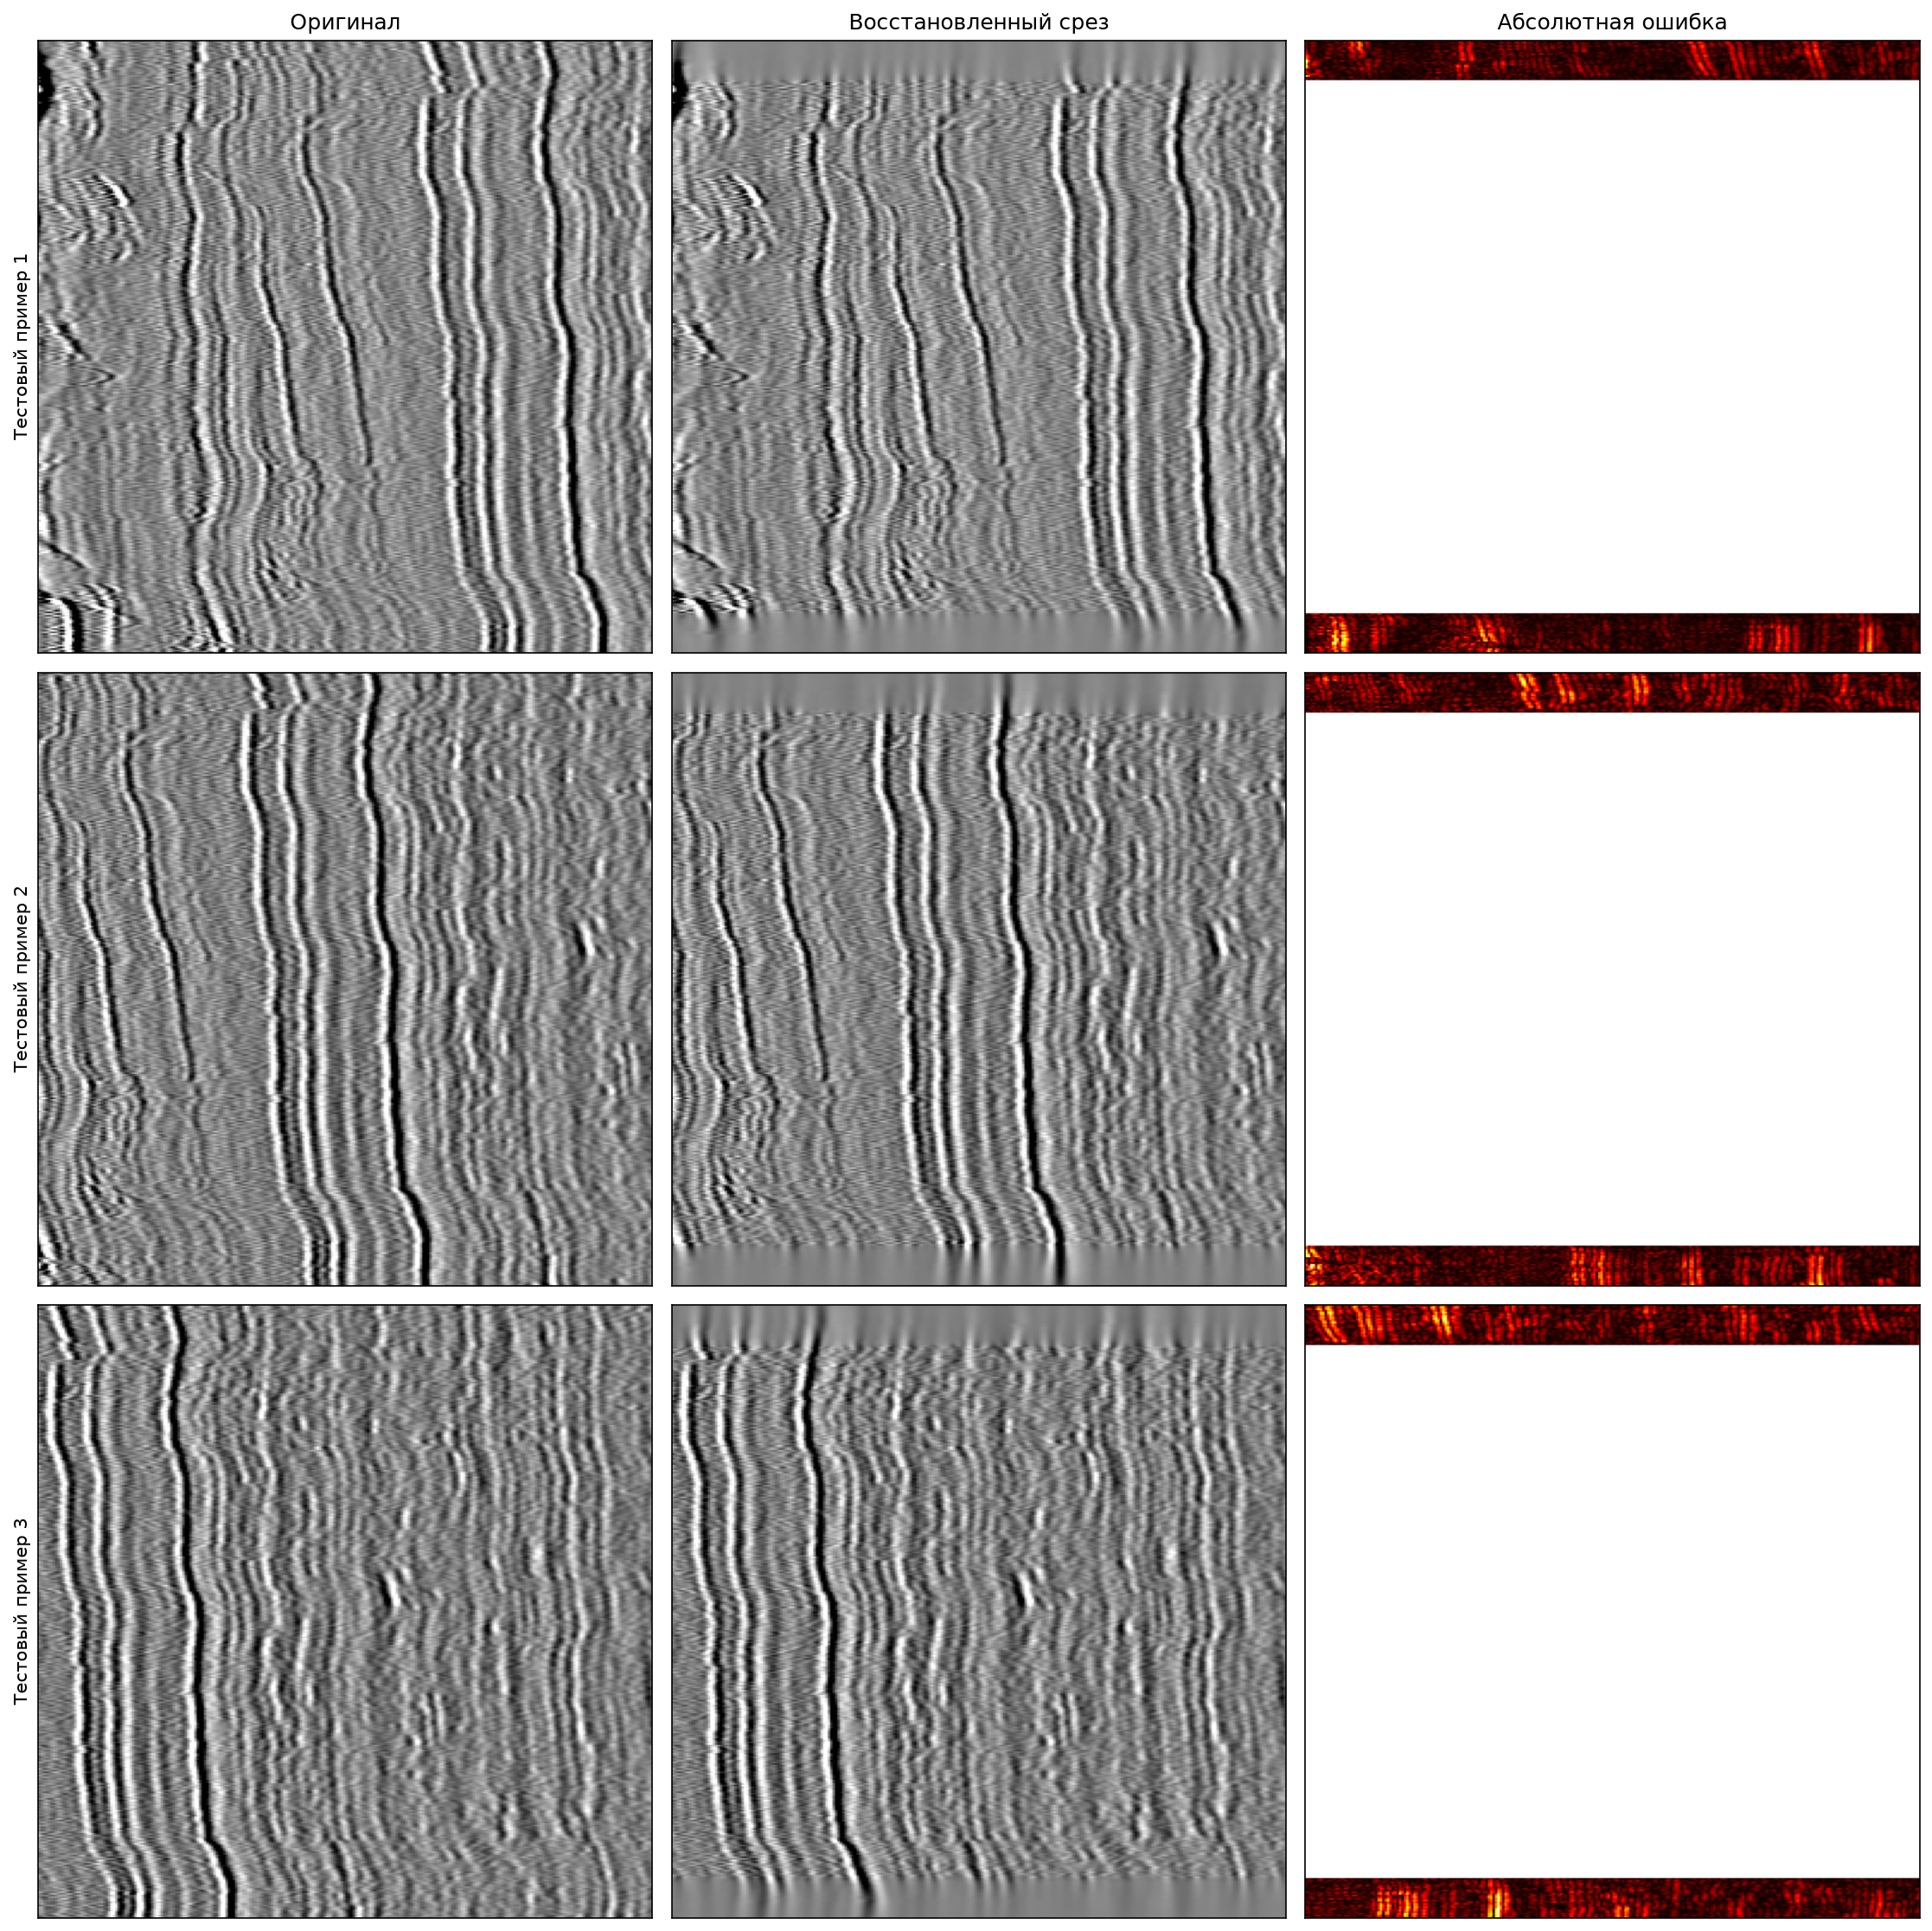

In [19]:
inputs, target, mask = next(iter(test_loader))
inputs = inputs.to(device)
target = target.to(device)
mask = mask.to(device)

with torch.inference_mode():
    with torch.autocast(device_type=device.type, enabled=use_amp):
        prediction = model(inputs)

examples = min(3, inputs.size(0))
fig, axes = plt.subplots(examples, 3, figsize=(15, 5 * examples))
titles = ("Оригинал", "Восстановленный срез", "Абсолютная ошибка")

for index in range(examples):
    original = target[index, 0].cpu().numpy() * std + mean
    predicted = prediction[index, 0].float().cpu().numpy() * std + mean
    sample_mask = mask[index, 0].cpu().numpy().astype(bool)

    restored = original.copy()
    restored[sample_mask] = predicted[sample_mask]

    error = np.full_like(original, np.nan)
    error[sample_mask] = np.abs(predicted[sample_mask] - original[sample_mask])

    a_min, a_max = np.percentile(original, [1, 99])
    panels = (
        (original, "gray", a_min, a_max),
        (restored, "gray", a_min, a_max),
        (error, "hot", None, None),
    )
    for column, (data, colormap, vmin, vmax) in enumerate(panels):
        axis = axes[index, column]
        axis.imshow(data, cmap=colormap, vmin=vmin, vmax=vmax, aspect="auto")
        axis.set_xticks([])
        axis.set_yticks([])

    axes[index, 0].set_ylabel(f"Тестовый пример {index + 1}")
    if index == 0:
        for column, title in enumerate(titles):
            axes[0, column].set_title(title)

fig.tight_layout()
fig.savefig("outpainting_test_examples.png", dpi=150, bbox_inches="tight")
display(Image("outpainting_test_examples.png"))


## Блок "Инференса модели"

Сеть полносвёрточная и использует локальные признаки, поэтому после обучения на патчах 368×256 применяется ко всему срезу 481×800. Вход дополняется до размеров, кратных 16, а результат обрезается до исходной формы.

На срезах 0, 1 и двух последних индексах несуществующие контекстные кадры заполняются нулями после нормализации. Это соответствует кодированию пропусков и не дублирует крайние кадры, чего не было в обучении.

Заполнение пропусков выполняется за один проход. Для каждого среза модель один раз предсказывает всю область пропусков. Визуализация отдельных срезов и сохранение куба используют один и тот же `restore_slice`.


In [ ]:
checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


def predict_region(index, source, mask):
    indices = np.arange(index - 2, index + 3)
    valid = (indices >= 0) & (indices < cube.shape[0])
    frames = np.zeros((5, *cube.shape[1:]), dtype=np.float32)
    frames[valid] = source[indices[valid]]
    frames = (frames - mean) / std
    frames[~valid] = 0
    frames *= (1 - mask)[None]

    inputs = np.concatenate((frames, mask[None]), axis=0)[None]
    inputs = torch.from_numpy(inputs).float().to(device)

    with torch.inference_mode():
        with torch.autocast(device_type=device.type, enabled=use_amp):
            prediction = model(inputs)

    prediction = prediction[0, 0].float().cpu().numpy()
    return prediction * std + mean


def restore_slice(index):
    region_mask = real_mask[index]
    prediction = predict_region(index, cube, region_mask.astype(np.float32))
    restored = cube[index].copy()
    restored[region_mask] = prediction[region_mask]
    return restored


In [ ]:
def slice_panels(index):
    restored = restore_slice(index)
    original = cube[index].copy()
    missing = real_mask[index]

    original_display = original.copy()
    original_display[missing] = np.nan

    restored_region = np.full_like(restored, np.nan)
    restored_region[missing] = restored[missing]

    known = original[~missing]
    a_min, a_max = np.percentile(known, [1, 99])
    return original_display, restored_region, restored, a_min, a_max


def show_restored_slice(index):
    original_display, restored_region, restored, a_min, a_max = slice_panels(index)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    panels = (
        (original_display, "Исходный срез"),
        (restored_region, "Восстановленная область"),
        (restored, "Результат"),
    )
    for column, (data, title) in enumerate(panels):
        axes[column].imshow(data, cmap="gray", vmin=a_min, vmax=a_max, aspect="auto")
        axes[column].set_title(title)
        axes[column].set_xticks([])
        axes[column].set_yticks([])

    fig.suptitle(f"Срез {index}")
    fig.tight_layout()
    fig.savefig("outpainting_restored_slice.png", dpi=150, bbox_inches="tight")
    display(Image("outpainting_restored_slice.png"))


In [ ]:
indices = np.linspace(0, cube.shape[0] - 1, 4).astype(int)
panels = [slice_panels(index) for index in indices]

titles = ("Исходный срез", "Восстановленная область", "Результат")
fig, axes = plt.subplots(len(indices), 3, figsize=(15, 5 * len(indices)))

for row, index in enumerate(indices):
    original_display, restored_region, restored, a_min, a_max = panels[row]
    for column, (data, title) in enumerate(zip((original_display, restored_region, restored), titles)):
        axis = axes[row, column]
        axis.imshow(data, cmap="gray", vmin=a_min, vmax=a_max, aspect="auto")
        axis.set_xticks([])
        axis.set_yticks([])
    axes[row, 0].set_ylabel(f"Срез {index}")
    if row == 0:
        for column, title in enumerate(titles):
            axes[0, column].set_title(title)

fig.tight_layout()
fig.savefig("outpainting_restored_slices.png", dpi=150, bbox_inches="tight")
display(Image("outpainting_restored_slices.png"))


## Блок сохранения артефактов

Код и информация о том, как сохранялась модель и восстановленный куб (shape финального куба должен совпадать с shape'ом входного куба, который был скачан по ссылке)

In [ ]:
restored_cube = cube.copy()

for index in tqdm(range(cube.shape[0]), desc="inference"):
    restored_cube[index] = restore_slice(index)

assert restored_cube.shape == cube.shape

output_path = "outpainting_cube_restored.npy"
model_output_path = "outpainting_unet_inference.pt"
np.save(output_path, restored_cube)
torch.save(model.state_dict(), model_output_path)
print(f"Восстановленный куб сохранен: {output_path}")
print(f"Модель для инференса сохранена: {model_output_path}")
